# 🔗 Live Deployment URL: **`PASTE YOUR STREAMLIT URL HERE AFTER DEPLOYMENT`**

> (Placeholder – replace with the real `https://<your-app>.streamlit.app` link once the app is deployed and tested. Assignment requires this link at the very top of the notebook.)

---

# Heart Disease Prediction System

| | |
|---|---|
| **Course** | Machine Learning Fundamentals (AIC354) |
| **Assignment** | Assignment 2 – Developing an End-to-End Machine Learning System (Task 2) |
| **University** | COMSATS University Islamabad, Lahore Campus |
| **Student Name** | `YOUR NAME` |
| **Registration No.** | `FA24-BSE-159` *(verify)* |
| **Implementation** | Jupyter Notebook (Python) |
| **Deployment** | Streamlit Community Cloud |

## Objectives
1. Obtain the **UCI Heart Disease** dataset and understand it.
2. Re-use the instructor's Titanic workflow (Load → Understand → Encode → Train → Test → Apply → Feedback → Deploy) for a new problem.
3. Use **exactly four input attributes** and the same algorithm as the instructor (**Support Vector Classifier, SVC**).
4. Evaluate the model with accuracy, precision, recall, F1-score and a confusion matrix.
5. Save the trained model and use it in a cloud-hosted web application.

## Task description
A **binary classification** problem: given a patient's **age, sex, chest-pain type and maximum heart rate**, predict whether **heart disease is present (1)** or **absent (0)**.

**Dataset source:** UCI Machine Learning Repository – Heart Disease, https://archive.ics.uci.edu/dataset/45/heart+disease  
**Version used:** `processed.cleveland.data` (Cleveland Clinic Foundation, 303 patients, 14 attributes).
Principal investigator credit (as requested by the dataset authors): Robert Detrano, M.D., Ph.D. (V.A. Medical Center, Long Beach and Cleveland Clinic Foundation); donor: David W. Aha.

> ⚠️ **Educational use only.** This model is a classroom exercise. It is **not** a medical diagnosis tool.

## Why `processed.cleveland.data`?
The UCI folder contains four hospitals (Cleveland, Hungarian, Switzerland, VA Long Beach) in several file versions:

| File | Meaning |
|---|---|
| `processed.cleveland.data` | Cleveland, **14 used attributes**, comma-separated, **no header**, `?` for missing – documented as clean and usable |
| `cleveland.data` | Raw 76-attribute version – the `WARNING` file says it is **corrupted/messed up** |
| `cleve.mod` | Cleveland re-coded as a symbolic (text) mixed dataset |
| `processed.hungarian/switzerland/va.data` | Other hospitals, same 14-column format but many missing values |
| `heart-disease.names`, `ask-detrano`, `Index`, `bak` | Documentation / notes / backup |

The `WARNING` file states that **`processed.cleveland.data` is in good shape**, and the documentation says it is the database used by ML researchers (the others contain many missing values). So it is the correct file for this assignment. We do **not** mix hospitals.

## Table of Contents
- Step 1: Import Libraries
- Step 2: Load the Dataset
- Step 3: Understand and Pre-process the Data (3.1 explore, 3.2 clean, 3.3 target)
- Step 4: Feature Selection – exactly four attributes
- Step 5: Encoding / Scaling (inside a pipeline)
- Step 6: Training Phase (split, train SVC, save model)
- Step 7: Testing Phase (load model, evaluate)
- Step 8: Application Phase (sample prediction)
- Step 9: Feedback Phase
- Step 10: Deployment (Streamlit Community Cloud)
- Conclusion and Requirement Checklist

### Step 1: Import Libraries

In [1]:
"""
Purpose: import the tools we need.
 - numpy / pandas      : numbers and tables (DataFrames)
 - matplotlib / seaborn: charts
 - pickle              : save / load the trained model (same as the instructor)
 - scikit-learn        : split data, preprocess, SVC model, metrics
"""
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn import svm
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load the Dataset
`processed.cleveland.data` has **no header row**, so we must give column names ourselves. The order below is taken from the official documentation (`heart-disease.names`, section 7 "Only 14 used"): attributes #3, #4, #9, #10, #12, #16, #19, #32, #38, #40, #41, #44, #51, #58.
Missing values are written as `?`, so we tell pandas `na_values="?"`.

In [2]:
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# The file 'processed.cleveland.data' must be in the same folder as this notebook
heart_data = pd.read_csv("processed.cleveland.data", header=None,
                         names=column_names, na_values="?")

print("Dataset loaded. First five records:\n")
heart_data.head()

Dataset loaded. First five records:



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Step 3: Understand and Pre-process the Data
#### Step 3.1: Understand the data

In [3]:
print("Shape (rows, columns):", heart_data.shape)
print("\nColumn names:", list(heart_data.columns))
print("\nData types and non-null counts:\n")
heart_data.info()

Shape (rows, columns): (303, 14)

Column names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Data types and non-null counts:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [4]:
print("Summary statistics:")
heart_data.describe().round(2)

Summary statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.94
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,1.23
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00


In [5]:
print("Missing values per column (the '?' placeholders were converted to NaN):\n")
print(heart_data.isna().sum())
print("\nTotal duplicate rows:", heart_data.duplicated().sum())

Missing values per column (the '?' placeholders were converted to NaN):

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Total duplicate rows: 0


**Observations (from the output above):** 303 rows × 14 columns; every column is numeric. Missing values exist **only** in `ca` (4) and `thal` (2) – neither is one of our four chosen inputs. There are no duplicate rows, so nothing needs to be removed.

**Attribute meanings in simple language**

| Attribute | Meaning | Type |
|---|---|---|
| `age` | Age in years | numeric |
| `sex` | 1 = male, 0 = female | categorical (binary) |
| `cp` | Chest-pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic | categorical |
| `trestbps` | Resting blood pressure (mm Hg) | numeric |
| `chol` | Serum cholesterol (mg/dl) | numeric |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = true) | binary |
| `restecg` | Resting ECG result (0 normal, 1 ST-T abnormality, 2 LV hypertrophy) | categorical |
| `thalach` | **Maximum heart rate achieved** during exercise test | numeric |
| `exang` | Exercise-induced angina (1 = yes) | binary |
| `oldpeak` | ST depression induced by exercise | numeric |
| `slope` | Slope of peak-exercise ST segment (1 up, 2 flat, 3 down) | categorical |
| `ca` | Major vessels (0–3) coloured by fluoroscopy | numeric |
| `thal` | Thalassemia test (3 normal, 6 fixed defect, 7 reversible defect) | categorical |
| `num` | **Target**: angiographic diagnosis, 0–4 | target |

#### Step 3.2: Define the target variable
According to the documentation the goal field `num` is 0 (no disease) to 4. Published experiments simply separate **absence (0)** from **presence (1, 2, 3, 4)**, so we convert it to a binary label.

Original target distribution (num):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Binary target distribution (target):
target
0    164
1    139
Name: count, dtype: int64

Check against UCI documentation for Cleveland: 164 healthy, 139 sick -> 164 healthy, 139 sick


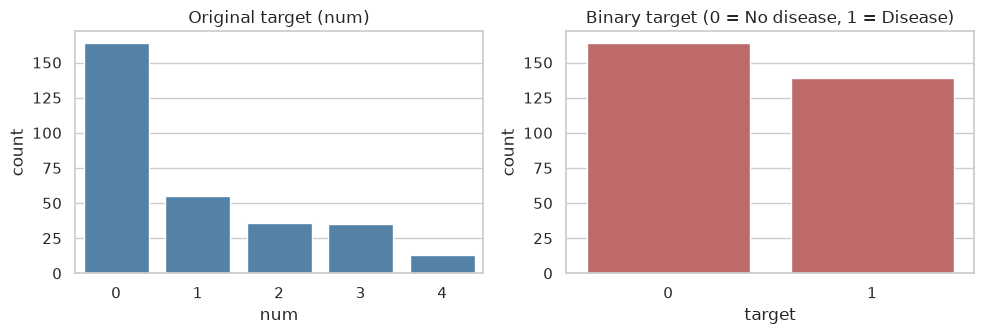

In [6]:
print("Original target distribution (num):")
print(heart_data["num"].value_counts().sort_index())

# 0 -> 0 (no heart disease); 1,2,3,4 -> 1 (heart disease present)
heart_data["target"] = (heart_data["num"] > 0).astype(int)

print("\nBinary target distribution (target):")
print(heart_data["target"].value_counts().sort_index())
print("\nCheck against UCI documentation for Cleveland: 164 healthy, 139 sick ->",
      (heart_data["target"] == 0).sum(), "healthy,", (heart_data["target"] == 1).sum(), "sick")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x="num", data=heart_data, ax=ax[0], color="steelblue")
ax[0].set_title("Original target (num)")
sns.countplot(x="target", data=heart_data, ax=ax[1], color="indianred")
ax[1].set_title("Binary target (0 = No disease, 1 = Disease)")
plt.tight_layout(); plt.show()

The binary classes are fairly balanced (about 54% vs 46%), so accuracy is a reasonable metric, but we will still report precision, recall and F1.

#### Step 3.3: Visual exploration of the data

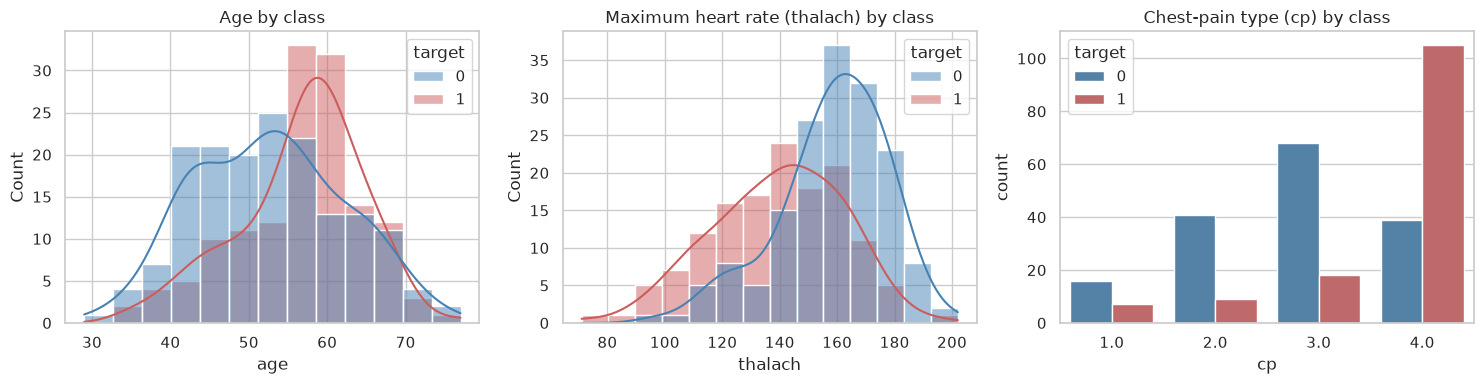

Share with heart disease, by sex (0 = female, 1 = male):
sex
0.0    0.26
1.0    0.55
Name: target, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=heart_data, x="age", hue="target", kde=True, ax=axes[0], palette=["steelblue", "indianred"])
axes[0].set_title("Age by class")
sns.histplot(data=heart_data, x="thalach", hue="target", kde=True, ax=axes[1], palette=["steelblue", "indianred"])
axes[1].set_title("Maximum heart rate (thalach) by class")
sns.countplot(data=heart_data, x="cp", hue="target", ax=axes[2], palette=["steelblue", "indianred"])
axes[2].set_title("Chest-pain type (cp) by class")
plt.tight_layout(); plt.show()

print("Share with heart disease, by sex (0 = female, 1 = male):")
print(heart_data.groupby("sex")["target"].mean().round(2))

**What the charts support:** patients with disease tend to have a **lower maximum heart rate**, and the **asymptomatic chest-pain type (cp = 4)** contains far more disease cases than the other types. Men have a higher share of disease than women in this sample. These are patterns in *this* dataset only.

#### Pre-processing summary (instructor's "Step 3.2 / Step 4")
- Missing values: only in `ca` and `thal`, which we do **not** use → no imputation is needed for our four inputs. (We still verify this in the next step with an assertion.)
- Duplicates: none → nothing removed.
- Feature extraction: the features are already available; we only select four.

### Step 4: Feature Selection – exactly four input attributes
We choose **`age`, `sex`, `cp`, `thalach`**:

| Feature | Why it is suitable | Type |
|---|---|---|
| `age` | Basic patient information; heart disease becomes more common with age | numeric |
| `sex` | Basic patient information; disease rate differs between sexes in the data | categorical (0/1) |
| `cp` | Type of chest pain is a key clinical symptom; `cp = 4` is strongly linked with disease in the chart above | categorical (1–4) |
| `thalach` | Max heart rate achieved; lower values are linked with disease | numeric |

All four are easy for a user to enter in a web form, have **no missing values**, and are not identifiers. The target (`target`) is kept completely separate.

**Limitation:** four attributes ignore very important information such as `ca`, `thal`, `oldpeak`, `exang`. The model will therefore be less accurate than models using all 13 inputs.

In [8]:
selected_features = ["age", "sex", "cp", "thalach"]     # exactly four inputs
target_column = "target"                                 # output

assert len(selected_features) == 4, "Exactly four input attributes are required"
assert target_column not in selected_features and "num" not in selected_features, "Target must not be an input"
assert heart_data[selected_features].isna().sum().sum() == 0, "Selected inputs must have no missing values"

print("Selected input attributes:", selected_features)
print("Number of inputs         :", len(selected_features))
print("Target                   :", target_column)

X = heart_data[selected_features].copy()
y = heart_data[target_column].copy()
print("\nX shape:", X.shape, " y shape:", y.shape)
X.head()

Selected input attributes: ['age', 'sex', 'cp', 'thalach']
Number of inputs         : 4
Target                   : target

X shape: (303, 4)  y shape: (303,)


,age,sex,cp,thalach
0,63.0,1.0,1.0,150.0
1,67.0,1.0,4.0,108.0
2,67.0,1.0,4.0,129.0
3,37.0,1.0,3.0,187.0
4,41.0,0.0,2.0,172.0


### Step 5: Encoding and Scaling (inside a pipeline)
The instructor used `LabelEncoder` because Titanic inputs were text. Our four inputs are already numbers, but they need different treatment:

- `age`, `thalach` – real numbers on different scales → **StandardScaler** (SVC is distance-based, so scaling matters).
- `sex` – already 0/1 → kept as is.
- `cp` – four *categories* (not an order) → **OneHotEncoder** with the fixed categories 1, 2, 3, 4.

Everything is wrapped in one scikit-learn **Pipeline** together with the SVC. The pipeline learns its scaling **only from the training data** (no data leakage) and the same steps are automatically applied to new user input.

In [9]:
numeric_features     = ["age", "thalach"]
binary_features      = ["sex"]
categorical_features = ["cp"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("bin", "passthrough", binary_features),
    ("cat", OneHotEncoder(categories=[[1, 2, 3, 4]], handle_unknown="ignore"), categorical_features),
])

# Same algorithm as the instructor: Support Vector Classifier (SVC)
heart_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("svc", svm.SVC(random_state=0)),
])
print(heart_model)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'thalach']),
                                                 ('bin', 'passthrough',
                                                  ['sex']),
                                                 ('cat',
                                                  OneHotEncoder(categories=[[1,
                                                                             2,
                                                                             3,
                                                                             4]],
                                                                handle_unknown='ignore'),
                                                  ['cp'])])),
                ('svc', SVC(random_state=0))])


### Step 6: Execute the Training Phase
#### Step 6.1: Split into training and testing data
80 % for training, 20 % for testing. `stratify=y` keeps the class proportions equal in both parts and `random_state` makes the split reproducible. (The instructor used `shuffle=False` because his toy rows alternate classes; real data should be shuffled.)
The test set is not touched until evaluation.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training inputs:", X_train.shape, " Training labels:", y_train.shape)
print("Testing inputs :", X_test.shape,  " Testing labels :", y_test.shape)
print("\nTraining class share:", y_train.value_counts(normalize=True).round(2).to_dict())
print("Testing class share :", y_test.value_counts(normalize=True).round(2).to_dict())

Training inputs: (242, 4)  Training labels: (242,)
Testing inputs : (61, 4)  Testing labels : (61,)

Training class share: {0: 0.54, 1: 0.46}
Testing class share : {0: 0.54, 1: 0.46}


#### Step 6.2: Train the Support Vector Classifier
Calling `fit` scales the numbers, one-hot encodes `cp` and trains the SVC using **only** the training data.

In [11]:
heart_model.fit(X_train, y_train)
print("Model trained.")
print("Features the model expects (in order):", list(heart_model.feature_names_in_))

Model trained.
Features the model expects (in order): ['age', 'sex', 'cp', 'thalach']


#### Step 6.3: Save the trained model
We save the **whole fitted pipeline** to a *new* file, `heart_disease_model.pkl` (the instructor's `svc_trained_model.pkl` is not used or overwritten).

In [12]:
with open("heart_disease_model.pkl", "wb") as f:
    pickle.dump(heart_model, f)
print("Saved: heart_disease_model.pkl")

Saved: heart_disease_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1 – 7.2: Load the saved model and predict on the testing data

In [13]:
with open("heart_disease_model.pkl", "rb") as f:
    model = pickle.load(f)
print("Model loaded from heart_disease_model.pkl")

# Confirm the loaded model expects exactly our four inputs in the right order
print("Inputs expected by loaded model:", list(model.feature_names_in_), "->", len(model.feature_names_in_), "inputs")
assert list(model.feature_names_in_) == selected_features

test_predictions = model.predict(X_test)

results = X_test.copy()
results["Actual"] = y_test
results["Predicted"] = test_predictions
results.to_csv("model-predictions.csv", index=False)
results.head(10)

Model loaded from heart_disease_model.pkl
Inputs expected by loaded model: ['age', 'sex', 'cp', 'thalach'] -> 4 inputs


,age,sex,cp,thalach,Actual,Predicted
219,59.0,1.0,4.0,182.0,0,1
271,66.0,1.0,4.0,138.0,0,1
89,51.0,0.0,3.0,149.0,0,0
101,34.0,1.0,1.0,174.0,0,0
67,54.0,1.0,3.0,165.0,0,0
244,60.0,0.0,3.0,96.0,0,1
185,63.0,0.0,2.0,179.0,0,0
233,74.0,0.0,2.0,121.0,0,0
168,35.0,1.0,4.0,156.0,1,1
197,45.0,0.0,4.0,152.0,0,0


#### Step 7.3: Accuracy, precision, recall and F1-score

In [14]:
acc  = accuracy_score(y_test, test_predictions)
prec = precision_score(y_test, test_predictions)
rec  = recall_score(y_test, test_predictions)
f1   = f1_score(y_test, test_predictions)

metrics_table = pd.DataFrame({"Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
                              "Score":  [acc, prec, rec, f1]}).round(3)
print(metrics_table.to_string(index=False))

print("\nClassification Report:\n")
print(classification_report(y_test, test_predictions,
                            target_names=["No heart disease (0)", "Heart disease (1)"]))

   Metric  Score
 Accuracy  0.836
Precision  0.846
   Recall  0.786
 F1-score  0.815

Classification Report:

                      precision    recall  f1-score   support

No heart disease (0)       0.83      0.88      0.85        33
   Heart disease (1)       0.85      0.79      0.81        28

            accuracy                           0.84        61
           macro avg       0.84      0.83      0.83        61
        weighted avg       0.84      0.84      0.84        61



                    Predicted: No disease  Predicted: Disease
Actual: No disease                     29                   4
Actual: Disease                         6                  22


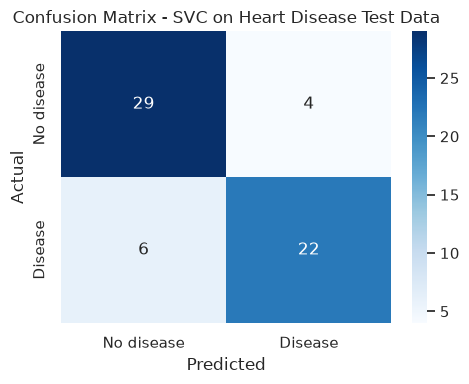

True negatives=29, False positives=4, False negatives=6, True positives=22


In [15]:
cm = confusion_matrix(y_test, test_predictions)
cm_df = pd.DataFrame(cm,
    index=["Actual: No disease", "Actual: Disease"],
    columns=["Predicted: No disease", "Predicted: Disease"])
print(cm_df)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Test Data")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives={tn}, False positives={fp}, False negatives={fn}, True positives={tp}")

**What the metrics mean (simple language)**
- **Accuracy** – out of all test patients, the share predicted correctly.
- **Precision** – of those the model called "disease", how many really had disease.
- **Recall** (sensitivity) – of all patients who really had disease, how many the model found.
- **F1-score** – one number balancing precision and recall.
- **Confusion matrix** – counts of correct and wrong predictions per class.

**Why recall and false negatives matter in health:** a *false negative* means a sick patient is told "no disease" and may miss treatment. A false positive usually only leads to extra tests. So in a real medical setting we would try to keep recall high, even at some cost to precision. (This classroom model must not be used for such decisions.)

**Limitations:** the test set has only 61 patients, so each patient changes accuracy by about 1.6 %; the data comes from one hospital, from patients who were referred for angiography; and only four attributes are used.

#### Step 7.4: Cross-validation – how stable is the result on a small dataset?
A single split on 303 rows can be lucky or unlucky. We therefore repeat training/testing 5 times (stratified 5-fold). The whole pipeline is re-fitted inside each fold, so there is no leakage.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(heart_model, X, y, cv=cv, scoring="accuracy")
cv_rec = cross_val_score(heart_model, X, y, cv=cv, scoring="recall")
print("5-fold accuracy per fold:", cv_acc.round(3), " mean = %.3f (+/- %.3f)" % (cv_acc.mean(), cv_acc.std()))
print("5-fold recall   per fold:", cv_rec.round(3), " mean = %.3f (+/- %.3f)" % (cv_rec.mean(), cv_rec.std()))

5-fold accuracy per fold: [0.803 0.82  0.705 0.767 0.783]  mean = 0.776 (+/- 0.040)
5-fold recall   per fold: [0.786 0.857 0.75  0.667 0.714]  mean = 0.755 (+/- 0.065)


### Step 8: Execute the Application Phase
#### Step 8.1: Take input from the user
Exactly four inputs, with the meaning and values defined by the dataset. As in the instructor's notebook, a demo patient is pre-filled so the notebook runs top-to-bottom without typing. To enter your own values, replace the four lines with `input()` calls.

In [17]:
age_input     = 58      # age in years
sex_input     = 1       # 1 = male, 0 = female
cp_input      = 4       # chest pain: 1 typical angina, 2 atypical angina, 3 non-anginal, 4 asymptomatic
thalach_input = 120     # maximum heart rate achieved (beats per minute)

print(f"age={age_input}, sex={sex_input}, cp={cp_input}, thalach={thalach_input}")

age=58, sex=1, cp=4, thalach=120


#### Step 8.2: Convert the input into a feature vector (same four columns, same order as the training data)

In [18]:
user_input = pd.DataFrame({
    "age":     [age_input],
    "sex":     [sex_input],
    "cp":      [cp_input],
    "thalach": [thalach_input],
})[selected_features]          # force the same column order
print(user_input)

   age  sex  cp  thalach
0   58    1   4      120


#### Step 8.3 – 8.5: Load the saved model and predict
The pipeline applies the **same fitted** scaling and encoding as in training automatically (the equivalent of the instructor's Step 8.3 label encoding).

In [19]:
with open("heart_disease_model.pkl", "rb") as f:
    model = pickle.load(f)

predicted_class = int(model.predict(user_input)[0])
label = "HEART DISEASE PRESENT (predicted class 1)" if predicted_class == 1 else "NO HEART DISEASE (predicted class 0)"

print("+" + "-" * 48 + "+")
print("|{:^48}|".format("** Prediction **"))
print("+" + "-" * 48 + "+")
print("|{:^48}|".format(label))
print("+" + "-" * 48 + "+")
print("\nThis is only the model's predicted class - NOT a medical diagnosis.")

+------------------------------------------------+
|                ** Prediction **                |
+------------------------------------------------+
|   HEART DISEASE PRESENT (predicted class 1)    |
+------------------------------------------------+

This is only the model's predicted class - NOT a medical diagnosis.


In [20]:
# Extra check: a few different sample patients through the same loaded model
samples = pd.DataFrame({
    "age":     [35, 45, 62, 70],
    "sex":     [0,  1,  1,  0],
    "cp":      [2,  3,  4,  4],
    "thalach": [180, 165, 105, 130],
})[selected_features]
samples["Prediction"] = np.where(model.predict(samples) == 1, "Disease present", "No disease")
samples

,age,sex,cp,thalach,Prediction
0,35,0,2,180,No disease
1,45,1,3,165,No disease
2,62,1,4,105,Disease present
3,70,0,4,130,Disease present


### Step 9: Execute the Feedback Phase
No real users or domain experts have tested this model yet, so we do **not** invent feedback. Instead we record what feedback should be collected and the improvements it would lead to.

#### Step 9.1: Feedback to collect
- From a cardiology / health domain expert: do predictions agree with clinical expectations (e.g. asymptomatic chest pain + low max heart rate → higher risk)?
- From student testers: are the four inputs clear and easy to enter in the web app?

#### Step 9.2: Potential improvements

In [21]:
improvements = [
    "Use more attributes (e.g. oldpeak, exang, ca, thal) - the assignment limits us to four, but accuracy would likely improve",
    "Use more data (e.g. combine hospitals after handling their many missing values) to reduce small-sample variability",
    "Tune SVC settings (C, gamma, kernel) with cross-validation instead of using defaults",
    "Compare other models (Logistic Regression, Random Forest) as a baseline",
    "Optimise for higher recall, since missing a sick patient is the costlier mistake",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more attributes (e.g. oldpeak, exang, ca, thal) - the assignment limits us to four, but accuracy would likely improve
2. Use more data (e.g. combine hospitals after handling their many missing values) to reduce small-sample variability
3. Tune SVC settings (C, gamma, kernel) with cross-validation instead of using defaults
4. Compare other models (Logistic Regression, Random Forest) as a baseline
5. Optimise for higher recall, since missing a sick patient is the costlier mistake


#### Step 9.3: Improve the model
In a next version we would retrain with the improvements above, re-run Steps 6–7, and replace `heart_disease_model.pkl` only if the cross-validated results get better.

### Step 10: Deploy the Model as a Public Web App (Streamlit Community Cloud)
Project files (all in one folder, e.g. a GitHub repo called `heart-disease-prediction`):
```
Heart_Disease_Prediction.ipynb
app.py
heart_disease_model.pkl
requirements.txt
runtime.txt
README.md
processed.cleveland.data
```
1. Create a free account at https://github.com and a **public** repository `heart-disease-prediction`.
2. Upload all the files above (Add file → Upload files).
3. Go to https://share.streamlit.io, sign in with GitHub → **Create app** → *Deploy a public app from GitHub*.
4. Repository: `<your-username>/heart-disease-prediction`, Branch: `main`, Main file path: `app.py`.
5. In **Advanced settings** choose **Python 3.11**, then **Deploy**.
6. When the build finishes, open the URL, test all four inputs, and paste the URL at the **top of this notebook**.

**Troubleshooting:** if you see `ModuleNotFoundError` or a pickle/version error, make sure `requirements.txt` pins `scikit-learn==1.7.2` (the version this model was trained with) and select Python 3.11 in the app settings. The model file and `app.py` must be in the same folder.

## Conclusion
We built an end-to-end heart-disease classifier following the instructor's workflow: data loading, exploration, target definition (0 vs 1–4), selection of exactly four inputs (`age`, `sex`, `cp`, `thalach`), training of a Support Vector Classifier inside a leakage-safe pipeline, evaluation on held-out data, saving/loading of the model, a sample prediction and a Streamlit web application. The scores printed in Step 7 are the real results of this run; because the data set is small and only four attributes are used, they should be treated as an educational estimate, not clinical performance.

## Requirement checklist
| Requirement | Where |
|---|---|
| UCI Heart Disease dataset | Step 2 (`processed.cleveland.data`) |
| Same workflow as Titanic notebook | Steps 1–10 |
| Exactly four inputs | Step 4 (assertion) |
| Same algorithm (SVC) | Step 5 / 6.2 |
| Evaluation metrics | Step 7.3, 7.4 |
| Model saved (`heart_disease_model.pkl`) and reloaded | Step 6.3, 7.1, 8.3 |
| Sample prediction | Step 8 |
| Cloud deployment + URL at top | Step 10 / top of notebook *(to be completed after deployment)* |